# 02 — The pipeline step by step

Every physical step of the plan is a function that works on plain numpy arrays, so it can be
inspected and tested without the catalog machinery. This notebook walks through

1. fluxes → 2. detection and bitmask → 3. confusion matrix and redshift assignment

on a mixture of two slices: step 219 (z ≈ 1.2, Hα and [O III] both in the grism) and step 148
(z ≈ 2.3, only [O III]/[O II]/Hβ in the grism), so single-line [O III] galaxies exist.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

In [2]:
from romanmock.io import open_catalog
from romanmock.lines import get_line_set

line_set = get_line_set("roman_transitions")
cols = line_set.required_columns + ["redshift_true", "redshift_obs", "gal_id"]

parts = []
for step in (219, 148):
    cat = open_catalog([f"{CATALOG}/lc_cores-{step}.diffsky_gals.hdf5"])
    parts.append(cat.take(200_000, at="start").select(*cols).get_data("numpy", wrap_single=True))
    cosmology = cat.cosmology
data = {c: np.concatenate([p[c] for p in parts]) for c in cols}
z_rsd = data["redshift_obs"]
print(len(z_rsd), "galaxies; z_rsd range", z_rsd.min().round(3), z_rsd.max().round(3))

400146 galaxies; z_rsd range 1.188 2.334


## 1. Fluxes

`feature_fluxes` sums the component columns of each feature and converts to erg/s/cm².

In [3]:
from romanmock import feature_fluxes

flux = feature_fluxes(data, line_set, data["redshift_true"], cosmology)   # (n, n_features)
print(flux.shape)
for i, feat in enumerate(line_set):
    print(f"{feat.name:<10s} median flux {np.median(flux[:, i]):.2e} erg/s/cm²")

(400146, 9)
Ha         median flux 4.45e-17 erg/s/cm²
Hb         median flux 8.17e-18 erg/s/cm²
OIII_5007  median flux 1.91e-17 erg/s/cm²
OIII_4959  median flux 6.23e-18 erg/s/cm²
OII_3727   median flux 4.62e-18 erg/s/cm²
SIII_9532  median flux 2.37e-17 erg/s/cm²
SIII_9069  median flux 9.12e-18 erg/s/cm²
OIII_4363  median flux 2.65e-20 erg/s/cm²
SIII_6312  median flux 1.66e-19 erg/s/cm²


## 2. Detection and the bitmask

A line is detectable if `F > F_lim(λ_obs)` with `λ_obs = λ₀ (1 + z_rsd)` inside the bandpass.
`ConstantFluxLimit` is the plan's initial model. Bit *i* of the bitmask is feature *i* of the
line set; `n_det = popcount(bitmask)`.

In [4]:
from romanmock import ConstantFluxLimit, ThresholdDetection, detect_lines, unpack_bitmask

rng = np.random.default_rng(0)
model = ThresholdDetection(ConstantFluxLimit(flux_limit=1e-16, wave_range=(10000.0, 19300.0)))
det = detect_lines(flux, z_rsd, line_set, model, rng)

print("bitmask dtype", det.bitmask.dtype, "| example bitmasks", det.bitmask[:8])
print("n_det       ", det.n_det[:8])
print("bit 0 (Ha) of the first 8:", unpack_bitmask(det.bitmask[:8], len(line_set))[:, 0].astype(int))

bitmask dtype uint32 | example bitmasks [1 0 0 0 1 0 0 0]
n_det        [1 0 0 0 1 0 0 0]
bit 0 (Ha) of the first 8: [1 0 0 0 1 0 0 0]


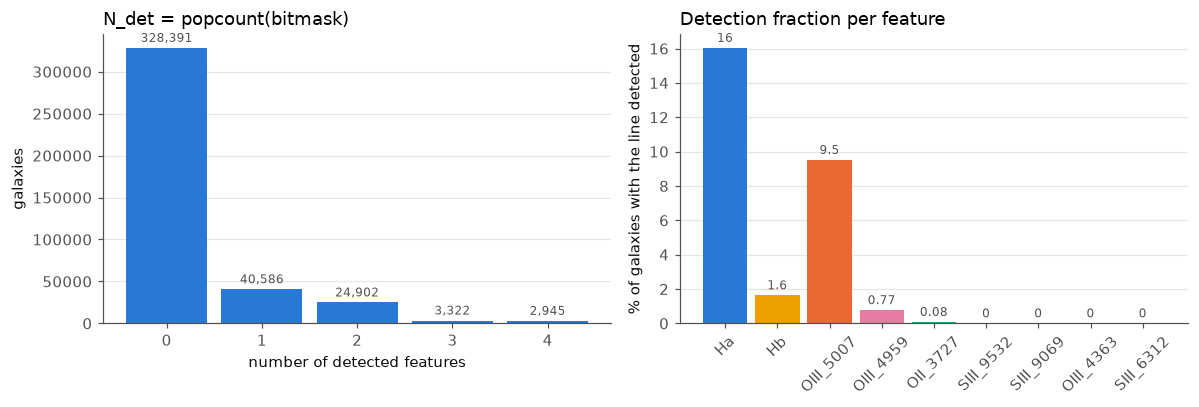

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
counts = np.bincount(det.n_det, minlength=5)
plotting.bar(ax1, [str(i) for i in range(len(counts))], counts)
ax1.set_xlabel("number of detected features"); ax1.set_ylabel("galaxies"); ax1.set_title("N_det = popcount(bitmask)")

frac = det.detected.mean(axis=0)
plotting.bar(ax2, line_set.names, frac * 100, colors=[plotting.feature_color(n) for n in line_set.names])
ax2.set_ylabel("% of galaxies with the line detected"); ax2.set_title("Detection fraction per feature")
ax2.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 3. Confusion matrix and redshift assignment

For `N_det ≥ 2` the redshift is taken as correct (`z_assigned = z_rsd`). For `N_det = 1` an identity
is drawn from `C_ij = P(assigned j | true i)`, with an explicit fail column, and
`z_assigned = λ_i (1 + z_rsd) / λ_j − 1`. The matrix below is an assumed scenario, not a calibration.

In [6]:
from romanmock import ConfusionMatrix, assign_redshifts, IdOutcome

cm = ConfusionMatrix.from_dict(line_set, {
    "Ha":        {"OIII_5007": 0.05, "OII_3727": 0.03, "fail": 0.05},
    "OIII_5007": {"Ha": 0.15, "OII_3727": 0.05, "fail": 0.05},
    "OII_3727":  {"Ha": 0.15, "OIII_5007": 0.10, "fail": 0.10},
    "Hb":        {"Ha": 0.30, "OIII_5007": 0.30, "fail": 0.20},
}, default_p_fail=0.02)
print(cm)
za = assign_redshifts(det, z_rsd, line_set, cm, rng)
for o in IdOutcome:
    print(f"{o.value} {o.name:<15s} {int((za.outcome == o).sum()):>9,}")

ConfusionMatrix(['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312'], diag=[0.87, 0.2, 0.75, 0.98, 0.65, 0.98, 0.98, 0.98, 0.98], p_fail=[0.05, 0.2, 0.05, 0.02, 0.1, 0.02, 0.02, 0.02, 0.02])
0 NOT_DETECTED      328,391
1 MULTI_LINE         31,169
2 SINGLE_CORRECT     34,594
3 SINGLE_MISID        3,960
4 SINGLE_FAILED       2,032


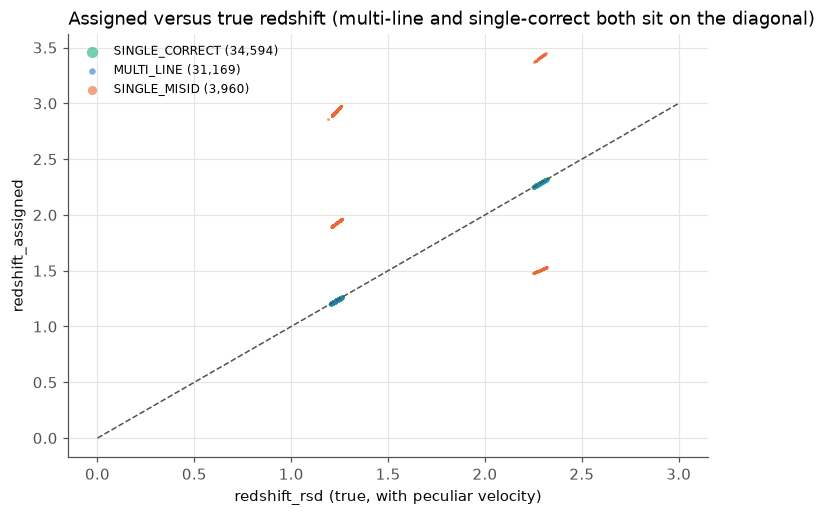

In [7]:
sel = rng.random(len(z_rsd)) < 0.1     # thin for plotting
fig, ax = plt.subplots(figsize=(7.5, 5))
for name, size in [("SINGLE_CORRECT", 6), ("MULTI_LINE", 2), ("SINGLE_MISID", 4)]:
    m = sel & (za.outcome == IdOutcome[name])
    ax.scatter(z_rsd[m], za.z_assigned[m], s=size, color=plotting.OUTCOME_COLORS[name], alpha=0.6, lw=0,
               label=f"{name} ({int((za.outcome == IdOutcome[name]).sum()):,})", rasterized=True)
ax.plot([0, 3], [0, 3], color=plotting.TEXT_SECONDARY, lw=1, ls="--")
ax.set_xlabel("redshift_rsd (true, with peculiar velocity)"); ax.set_ylabel("redshift_assigned")
ax.set_title("Assigned versus true redshift (multi-line and single-correct both sit on the diagonal)")
ax.legend(markerscale=3, fontsize=8); plt.show()

The off-diagonal streaks are the interloper tracks, e.g. [O III] 5007 at z ≈ 2.3 assigned as Hα
lands at an assigned redshift (1+2.3)·5008/6565 − 1 ≈ 1.5.

The sampling reproduces the input matrix: compare it with the empirical confusion among
single-line galaxies.

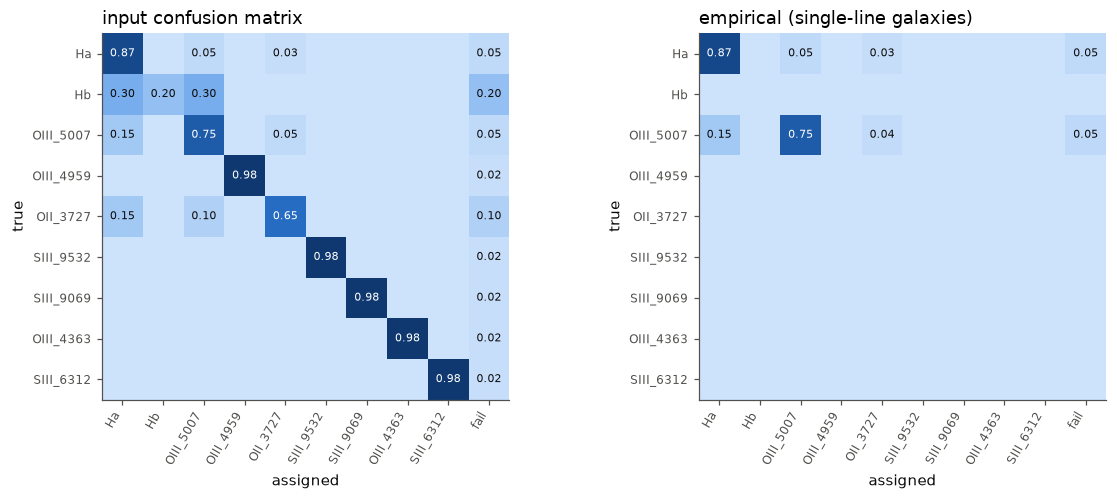

rows with no single-line galaxies in this subsample are empty in the empirical matrix


In [8]:
from romanmock.diagnostics import empirical_confusion

emp = empirical_confusion({"n_det": det.n_det, "line_true": za.line_true, "line_assigned": za.line_assigned}, line_set)
names = line_set.names + ["fail"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, mat, title in zip(axes, [cm.matrix, emp], ["input confusion matrix", "empirical (single-line galaxies)"]):
    im = ax.imshow(mat, cmap=plotting.sequential_cmap(), vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(line_set)), line_set.names, fontsize=8)
    ax.set_xlabel("assigned"); ax.set_ylabel("true"); ax.set_title(title); ax.grid(False)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if mat[i, j] > 0.005:
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if mat[i, j] > 0.5 else plotting.TEXT_PRIMARY)
plt.tight_layout(); plt.show()
print("rows with no single-line galaxies in this subsample are empty in the empirical matrix")

## The same thing through the pipeline object

`RomanMockPipeline.process_arrays` runs exactly these steps from a configuration and returns the
output columns of the catalog.

In [9]:
from romanmock import RomanMockConfig, RomanMockPipeline

cfg = RomanMockConfig.from_dict({
    "line_set": "roman_transitions",
    "sensitivity": {"type": "constant", "flux_limit": 1e-16, "wave_range": [10000.0, 19300.0]},
    "confusion": {"type": "matrix", "default_p_fail": 0.02, "rows": cm.to_dict()["rows"]},
    "output": {"store_snr": True},
})
pipe = RomanMockPipeline(cfg)
out = pipe.process_arrays(data, cosmology, np.random.default_rng(0))
print(list(out))
print("identical bitmasks:", np.array_equal(out["line_bitmask"], det.bitmask))

['Ha_snr', 'Hb_snr', 'OIII_5007_snr', 'OIII_4959_snr', 'OII_3727_snr', 'SIII_9532_snr', 'SIII_9069_snr', 'OIII_4363_snr', 'SIII_6312_snr', 'redshift_rsd', 'redshift_assigned', 'id_outcome', 'line_bitmask', 'n_det', 'line_true', 'line_assigned']
identical bitmasks: True
